In [1]:
from pathlib import Path
import re
import json 
import sys
import os

import copy

import matplotlib
import matplotlib.pyplot as plt
# %matplotlib notebook
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns  
import pickle as pkl
from tqdm import tqdm
from tensorboard.backend.event_processing import event_accumulator
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import as_completed

module_path = os.path.abspath(os.path.join('../'))
if module_path not in sys.path:
    sys.path.append(module_path)


### Plot settings

In [2]:
#font_size = 9
#matplotlib.rcParams['font.size'] = font_size
#matplotlib.rcParams["font.weight"] = "bold"
#matplotlib.rcParams['text.usetex'] = True
#matplotlib.rcParams['axes.labelsize'] = font_size
#matplotlib.rcParams['axes.titlesize'] = 10
#matplotlib.rcParams['legend.fontsize'] = font_size
#matplotlib.rcParams['xtick.labelsize'] = font_size
#matplotlib.rcParams['ytick.labelsize'] = font_size
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec
fs_m1 = 7  # for figure ticks
fs = 9  # for regular figure text
fs_p1 = 10  # figure titles

axes_lw = 0.9

figwidth = 6.6

matplotlib.rc('font', size=fs)          # controls default text sizes
matplotlib.rc('axes', titlesize=fs)     # fontsize of the axes title
matplotlib.rc('axes', labelsize=fs)    # fontsize of the x and y labels
matplotlib.rc('axes', linewidth=axes_lw)    # fontsize of the x and y labels
matplotlib.rc('xtick', labelsize=fs_m1)    # fontsize of the tick labels
matplotlib.rc('ytick', labelsize=fs_m1)    # fontsize of the tick labels
matplotlib.rc('legend', fontsize=fs_m1)    # legend fontsize
matplotlib.rc('figure', titlesize=fs_p1)  # fontsize of the figure title

matplotlib.rc('font', **{'family': 'serif', 'serif': ['Times New Roman']})

matplotlib.rc('text', usetex=True)

plt.rcParams.update({'text.latex.preamble': r'\usepackage{amsfonts}'})

def remove_xticks(ax):
    for tick in ax.xaxis.get_major_ticks():
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
    ax.xaxis.set_tick_params(which='minor', bottom=False, top=False)
    ax.xaxis.set_tick_params(which='major', bottom=False, top=False)
    ax.set_xticklabels([])

def remove_yticks(ax):
    for tick in ax.yaxis.get_major_ticks():
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
    ax.yaxis.set_tick_params(which='minor', left=False)
    ax.set_yticklabels([])

def smooth_mu_std(mu, std, N=6):
    mu_s = np.convolve(mu, np.ones(N)/N, mode='valid')
    std_s = np.convolve(std, np.ones(N)/N, mode='valid')
    
    return mu_s, std_s

In [3]:
def read_tb_file(tb_file):
    ea = event_accumulator.EventAccumulator(str(tb_file),
                                            size_guidance={ 
                                                event_accumulator.COMPRESSED_HISTOGRAMS: 0,
                                                event_accumulator.IMAGES: 0,
                                                event_accumulator.AUDIO: 0,
                                                event_accumulator.SCALARS: 0,
                                                event_accumulator.HISTOGRAMS: 0,})
    ea.Reload()
    return ea


def create_df_from_ea(ea, tag):
    steps = [x.step for x in ea.Scalars(tag)]
    values = [x.value for x in ea.Scalars(tag)]
    t0 = ea.Scalars(tag)[0].wall_time
    time = [x.wall_time-t0 for x in ea.Scalars(tag)]

    df = pd.DataFrame({"Time": time, "Step": steps, "Value": values})
    return df

def get_hparams_from_ea(ea):
    hparams_string = ea.Tensors('hyperparameters/text_summary')[0].tensor_proto.string_val[0].decode()
    hparams_l = hparams_string.replace('|\n|',',').replace('|',':').replace(':param:value,-:-,','').split(',')
    keys = [i.split(':')[0] for i in hparams_l if len(i.split(':'))>1]
    values = [i.split(':')[1] for i in hparams_l if len(i.split(':'))>1]
        
    d = {k:v for k,v in zip(keys,values)}
    
    return d

def create_mu_std_df_from_ea(ea_dict, tag, filter_best=False, n_best=5):
    min_len = 1e6
    
    df_list = []
    for name, ea in ea_dict.items():
        df = create_df_from_ea(ea, tag)
        if len(df) < min_len:
            min_len = len(df)
        df_list.append(df)

    return create_mu_std_df(df_list, filter_best, n_best)

def create_mu_std_df(df_list, filter_best=False, n_best=5):
    print(df_list)
    val_list = []
    for df in df_list:
        val_list.append(df["Value"])
    val_list = np.array(val_list)
    
    means = np.mean(val_list, axis=-1)
    idx = np.argsort(-means)
    if filter_best:
        vals = val_list[idx[:n_best]]
    else:
        vals = val_list
    x_axis = df_list[0]["Step"][:min_len]
    
    mu = np.mean(vals, axis=0)
    median = np.median(vals, axis=0)
    std = np.std(vals, axis=0)
    q1 = np.quantile(vals, 0.25, axis=0)
    q3 = np.quantile(vals, 0.75, axis=0)
    best = val_list[idx[0]]
    return pd.DataFrame({"Step": x_axis, "mu": mu, "std": std, "best": best, "median": median, "q1": q1, "q3": q3})

def load_dirs(tasks_dir, tags, save_path=None):
    # init dicts
    df_dict = {}
    for tag in tags:
        df_dict[tag] = {}
        
    for task_dir in tqdm(tasks_dir.iterdir()):        
        ea_dict = {}

        if len(list((task_dir).iterdir())) > 0:
            try:
                ea_dict[task_dir] = read_tb_file(task_dir)
            except:
                print(f"WARNING: No data in {run_dir}. Skipped.")
                continue

        if ea_dict:
            for tag in tags:
                df_dict[tag][task_dir.name] = create_mu_std_df(
                    ea_dict, tag, filter_best=True, n_best=5).copy()
    
    if save_path:
        with open(save_path, 'wb') as handle:
            pkl.dump(df_dict, handle, protocol=pkl.HIGHEST_PROTOCOL)
    return df_dict

def plot_mu_std(x_axis, mu, q1=None, q3=None, std=None, fig=None, title=None, label='', yuplim=None, 
                ydownlim=None, interpolate=False, max_num_tasks=None):
    if fig is None:
        fig = plt.figure(figsize=[12,10])
        
    if interpolate:
        from scipy.interpolate import make_interp_spline, BSpline
        std = std[::2]
        new_size = std.shape[0]
        
        xnew = np.linspace(x_axis.min(), x_axis.max(), new_size)
        spl = make_interp_spline(x_axis, mu, k=3)  # type: BSpline
        power_smooth = spl(xnew)
        
        x_axis = xnew
        power_smooth = np.clip(power_smooth, np.min(mu), np.max(mu))
        mu = power_smooth

    if std is not None:
        uperror = mu+std
        downerror = mu-std
        
        uperror = np.clip(uperror, np.min(mu), np.max(mu))
        downerror = np.clip(downerror, np.min(mu), np.max(mu))
    else:
        uperror = q3
        downerror = q1    
    
    if yuplim is not None:
        uperror = np.where(uperror > yuplim, yuplim, uperror)
    if ydownlim is not None:
        downerror = np.where(downerror < ydownlim, ydownlim, downerror)
    plt.plot(x_axis, mu, label=label)
    plt.fill_between(x_axis, downerror, uperror, alpha=.1)
    plt.xlabel("Timesteps", fontsize=16)
    plt.yticks(fontsize=16)
    plt.xticks(fontsize=16)
    
    if title is not None:
        plt.title(title)

#     plt.ticklabel_format(axis="x", style="sci", scilimits=(0,0))
    if max_num_tasks:
        plt.yticks(np.arange(max_num_tasks+1), 
                   ["{0:1.1f}\%".format(100.0 * i/max_num_tasks) for i in np.arange(max_num_tasks+1)])
#     plt.legend(loc="lower right")
#     plt.legend(loc="upper left")
    
    return fig

def create_mean_std_plot(ea_dict, tag,  title, smoothing=3.0, savefig_fmt=None, filter_best=False):
    df = create_mu_std_df(ea_dict, tag)
    fig = plot_mu_std(title, 'forward',df["steps"], df["mu"], df["std"])
    if savefig_fmt is not None:
        plt.savefig(title + '.' + savefig_fmt, format=savefig_fmt, dpi=300)
        
    return fig

def parse_fname(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)
    seed = intgr[-4]
    n_epc = intgr[-1]
    n_epi = intgr[-2]
    if len(floats) > 0:
        irm_coeff = floats[0]
    else:
        irm_coeff = 0
        
    return int(seed), float(irm_coeff), name

In [4]:
#ea_dict = pkl.load(open('220923_swil_results.pkl','rb'))
ea_dict_swil = pkl.load(open('220923_swil_results.pkl','rb'))
ea_dict_gail = pkl.load(open('250923_gail.pkl','rb'))
ea_dict_airl = pkl.load(open('250923_airl_results.pkl','rb'))


In [5]:
###

In [6]:
seeds = [515, 234, 894, 322, 72]

algos = ['sac']
disc_types = ['gail']
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
lins = ['', '--irm_coeff=1.0', '--lip_coeff=1.0', '--use_spectral_norm', '--use_absorb_wrapper']
usenobs = ['', '--use_actions']
use_acs = ['']
subsamplings = [1,20,100]
periods = [100, -1]
n_demos = [1,4,10]
ent_coeffs = [0.0]
disc_nonlins = ['tanh']
qlens = [1]

d = {}

for env_name in envs:
    d[env_name] = {}
    for seed in seeds:
        d[env_name][seed] = {}
        for ss in subsamplings:
            d[env_name][seed][f"ss_{ss}"] = {}
            for n_demo in n_demos:
                d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"]  = {}
                for lin in lins:
                    d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin]  = {}
                    for ua in usenobs:
                        d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua]  = {}
                        for d_nl in disc_nonlins:                        
                            d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl]  = {}
                            for disc_type in disc_types:
                                d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type]  = {}
                                for per in periods:
                                    d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type][f"per_{per}"]  = {}
                                    for qlen in qlens:
                                        d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type][f"per_{per}"][f"ql_{qlen}"]  = {}


In [7]:
d_gail = copy.deepcopy(d)

In [8]:
seeds = [515, 234, 894, 322, 72]

algos = ['sac']
disc_types = ['airl']
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
lins = ['', '--lip_coeff=10.0--use_absorb_wrapper', '--use_spectral_norm', '--irm_coeff=1.0']
usenobs = ['', '--use_actions']
use_acs = ['']

subsamplings = [1,20,100]
periods = [-1]
n_demos = [1,4,10]

ent_coeffs = [0.0]

disc_nonlins = ['tanh']

qlens = [1]

d = {}

for env_name in envs:
    d[env_name] = {}
    for seed in seeds:
        d[env_name][seed] = {}
        for ss in subsamplings:
            d[env_name][seed][f"ss_{ss}"] = {}
            for n_demo in n_demos:
                d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"]  = {}
                for lin in lins:
                    d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin]  = {}
                    for ua in usenobs:
                        d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua]  = {}
                        for d_nl in disc_nonlins:                        
                            d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl]  = {}
                            for disc_type in disc_types:
                                d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type]  = {}
                                for per in periods:
                                    d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type][f"per_{per}"]  = {}
                                    for qlen in qlens:
                                        d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type][f"per_{per}"][f"ql_{qlen}"]  = {}

                            

In [9]:
d_airl = copy.deepcopy(d)

In [10]:
seeds = [515, 234, 894, 322, 72]

algos = ['sac']
disc_types = ['swil']
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
lins = ['', '--replace_atoms']
usenobs = ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']
use_acs = ['']
n_demos = [1,4,10]

qlens = [1,5,10]
subsamplings = [1,20,100]
ent_coeffs = [0.0]
periods = [100]
disc_nonlins = ['tanh']

d = {}

for env_name in envs:
    d[env_name] = {}
    for seed in seeds:
        d[env_name][seed] = {}
        for ss in subsamplings:
            d[env_name][seed][f"ss_{ss}"] = {}
            for n_demo in n_demos:
                d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"]  = {}
                for lin in lins:
                    d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin]  = {}
                    for ua in usenobs:
                        d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua]  = {}
                        for d_nl in disc_nonlins:                        
                            d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl]  = {}
                            for disc_type in disc_types:
                                d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type]  = {}
                                for per in periods:
                                    d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type][f"per_{per}"]  = {}
                                    for qlen in qlens:
                                        d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type][f"per_{per}"][f"ql_{qlen}"]  = {}


In [11]:
d_swil = copy.deepcopy(d)

In [12]:
cnt = 0
for k, v in ea_dict_swil.items():

    if 'sac_swil' in str(k):
        hparams = v[2]
        lin_string = ""
        if hparams['replace_atoms'] == 'True':
            lin_string += "--replace_atoms"
            
        nob_string = ""
        if hparams['use_next_obs'] == 'True':
            nob_string += "--use_next_obs"
        if hparams['use_actions'] == 'True':
            nob_string += "--use_actions"
        if hparams['use_dones'] == 'True':
            nob_string += "--use_dones"
        
        n_demos = f"nd_{hparams['n_demos']}"
        env_name = hparams['env_id']
        seed = int(hparams['seed'])

        if 'gail' in str(k):
            disc_type = 'gail'
        elif 'airl' in str(k):
            disc_type = 'airl'
        elif 'swil' in str(k):
            disc_type = 'swil'
        else:
            disc_type = 'wail'
        
        d_nl = hparams['disc_nonlin']
        ss = int(hparams['subsample'])
        qlen = int(hparams['max_q_len'])

        #print(env_name, seed, n_proj, n_demos, lin_string, nob_string, d_nl)
        d_swil[env_name][seed][f"ss_{ss}"][n_demos][lin_string][nob_string][d_nl][disc_type][f"per_{per}"][f"ql_{qlen}"]  = v

print(cnt)

0


In [13]:
for k, v in ea_dict_gail.items():
    if 'sac_gail' in str(k):
        hparams = v[2]
        lin_string = ""
        if hparams['use_weight_norm'] == 'True':
            lin_string += "--use_weight_norm"
        if hparams['use_spectral_norm'] == 'True':
            lin_string += "--use_spectral_norm"
        if hparams['use_absorb_wrapper'] == 'True':
            lin_string += "--use_absorb_wrapper"
        if float(hparams['lip_coeff']) > 0:            
            lin_string += f"--lip_coeff={hparams['lip_coeff']}"
        if float(hparams['irm_coeff']) > 0:            
            lin_string += f"--irm_coeff={hparams['irm_coeff']}"

        nob_string = ""
        #if hparams['use_next_obs'] == 'True':
        #    nob_string += "--use_next_obs"
        if hparams['use_actions'] == 'True':
            nob_string += "--use_actions"
        #if hparams['use_dones'] == 'True':
        #    nob_string += "--use_dones"

        ec = hparams['ent_coef']
        n_demos = f"nd_{hparams['n_demos']}"
        env_name = hparams['env_id']
        seed = int(hparams['seed'])
        
        if 'gail' in str(k):
            disc_type = 'gail'
        elif 'airl' in str(k):
            disc_type = 'airl'
        elif 'swil' in str(k):
            disc_type = 'swil'
        else:
            disc_type = 'wail'
        
        d_nl = hparams['disc_nonlin']
        ss = int(hparams['subsample'])
        per = int(hparams['disc_update_period'])
        #print(env_name, seed, n_proj, n_demos, lin_string, nob_string, d_nl)
        #print(k)
        #print(env_name, seed, ss, n_demos, lin_string, nob_string, d_nl, per)
        d_gail[env_name][seed][f"ss_{ss}"][n_demos][lin_string][nob_string][d_nl][disc_type][f"per_{per}"][f"ql_1"]  = v


In [14]:
for k, v in ea_dict_airl.items():
    if 'sac_airl' in str(k):
        hparams = v[2]
        lin_string = ""
        if hparams['use_weight_norm'] == 'True':
            lin_string += "--use_weight_norm"
        if hparams['use_spectral_norm'] == 'True':
            lin_string += "--use_spectral_norm"

        if float(hparams['lip_coeff']) > 0:            
            lin_string += f"--lip_coeff={hparams['lip_coeff']}"
        if float(hparams['irm_coeff']) > 0:            
            lin_string += f"--irm_coeff={hparams['irm_coeff']}"
        if hparams['use_absorb_wrapper'] == 'True':
            lin_string += "--use_absorb_wrapper"
            
        nob_string = ""
        #if hparams['use_next_obs'] == 'True':
        #    nob_string += "--use_next_obs"
        if hparams['use_actions'] == 'True':
            nob_string += "--use_actions"
        #if hparams['use_dones'] == 'True':
        #    nob_string += "--use_dones"

        ec = hparams['ent_coef']
        n_demos = f"nd_{hparams['n_demos']}"
        env_name = hparams['env_id']
        seed = int(hparams['seed'])
        
        if 'gail' in str(k):
            disc_type = 'gail'
        elif 'airl' in str(k):
            disc_type = 'airl'
        elif 'swil' in str(k):
            disc_type = 'swil'
        else:
            disc_type = 'wail'
        
        d_nl = hparams['disc_nonlin']
        ss = int(hparams['subsample'])
        per = int(hparams['disc_update_period'])
        #print(env_name, seed, n_proj, n_demos, lin_string, nob_string, d_nl)
        #print(k)
        #print(env_name, seed, ss, n_demos, lin_string, nob_string, d_nl, per)
        d_airl[env_name][seed][f"ss_{ss}"][n_demos][lin_string][nob_string][d_nl][disc_type][f"per_{per}"][f"ql_1"]  = v


In [15]:
### cum.rew. plots

### GAIL

['', '--irm_coeff=1.0', '--lip_coeff=1.0', '--use_spectral_norm', '--use_absorb_wrapper']


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

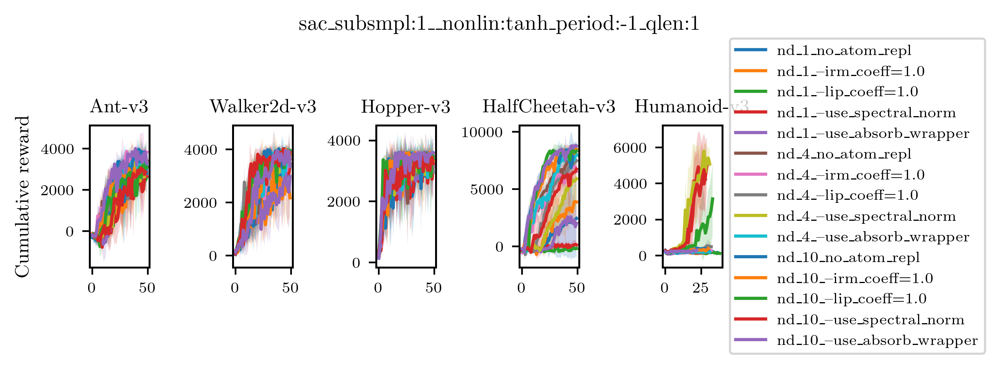

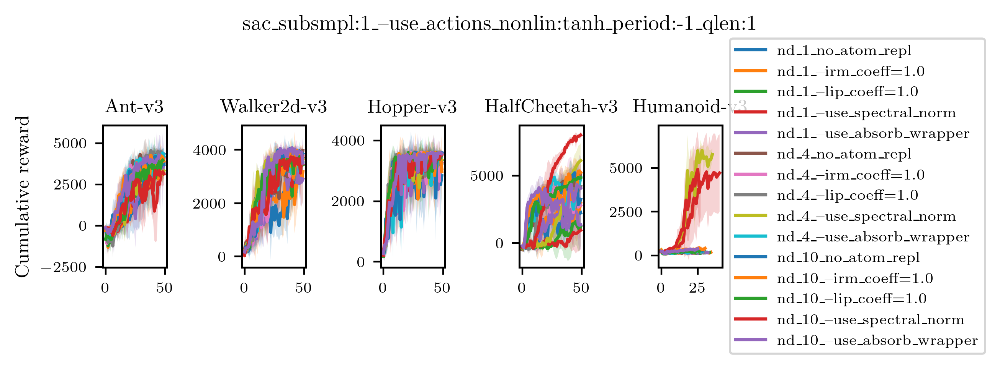

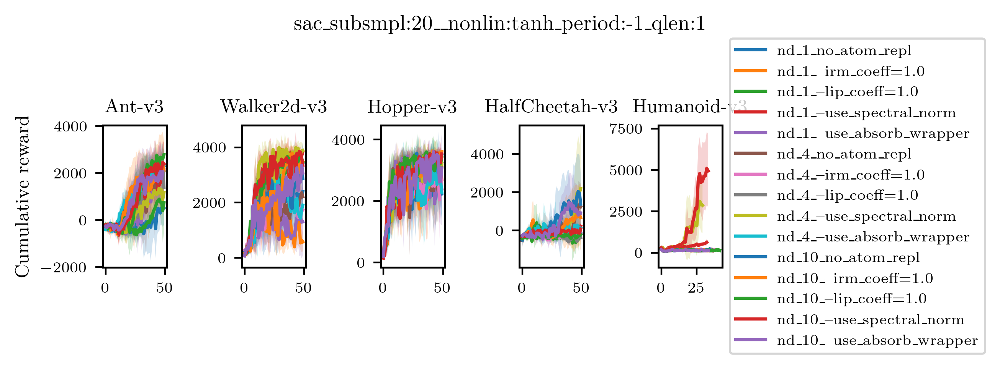

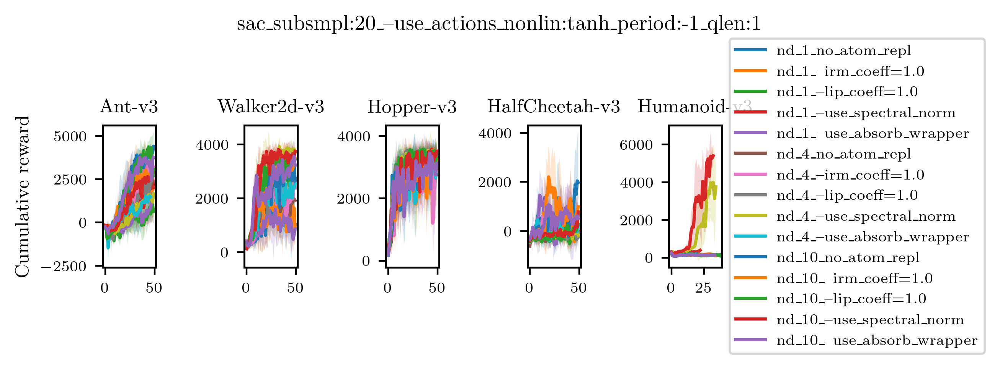

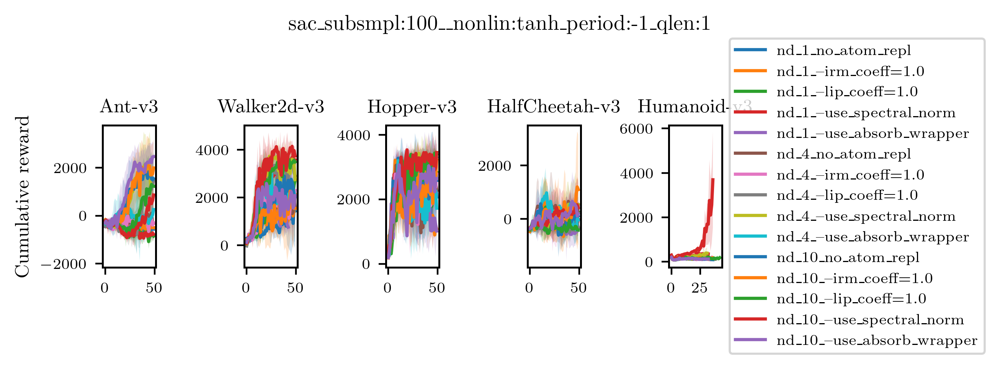

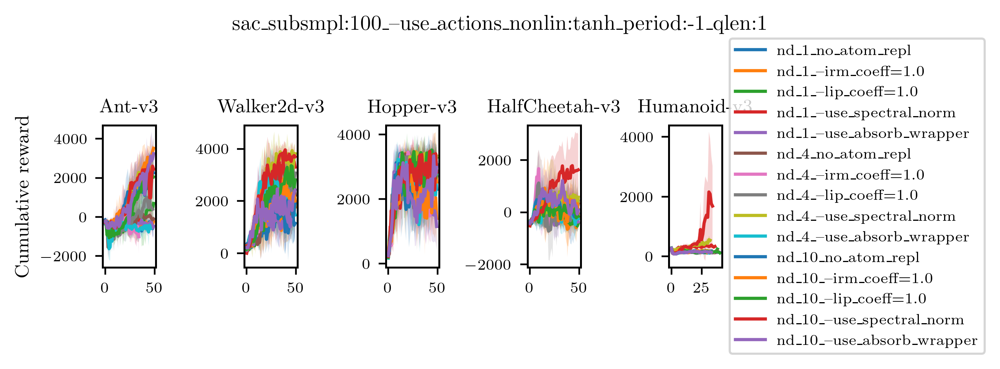

In [16]:
tags = ["charts/episodic_return", "irl/gail_bce_loss", "eval/mu"]

#nonlin="leakyrelu"
#lin = '--linear_proj'
#nob = ''
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']

algos = ['sac']
disc_types = ['gail']
lins = ['', '--irm_coeff=1.0', '--lip_coeff=1.0', '--use_spectral_norm', '--use_absorb_wrapper']
usenobs = ['', '--use_actions']

qlens = [1]
subsamplings = [1,20,100]
periods = [-1]
disc_nonlins = ['tanh']
print(lins)
n_demos = [1,4,10]

d_mustd_gail = {}
for env in envs:
    d_mustd_gail[env] = {}
    for ss in subsamplings:
        d_mustd_gail[env][f"ss_{ss}"] = {}
        for n_demo in n_demos:
            d_mustd_gail[env][f"ss_{ss}"][f"nd_{n_demo}"]  = {}
            for lin in lins:
                d_mustd_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin]  = {}
                for ua in usenobs:
                    d_mustd_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua]  = {}
                    for per in periods:
                        d_mustd_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"]  = {}
                        for qlen in qlens:
                            d_mustd_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"][f"ql_{qlen}"]  = {}

subsample_plot = 2

for algo in algos:
    for ss in subsamplings:
        for nob in usenobs:
            for per in periods:
                for ql in qlens:
                    for nonlin in disc_nonlins:
                        fig, axs = plt.subplots(1,5, dpi=400, figsize=(figwidth, figwidth/3))
                        fig.tight_layout()
                        fig.subplots_adjust(top=0.88)
                        fig.suptitle(f"{algo}_subsmpl:{ss}_{nob}_nonlin:{nonlin}_period:{per}_qlen:{ql}")
                        #plt.style.use('ggplot')
                        #print(lin, nob, nonlin)
                        #plt.title(lin + nob + nonlin)
                        for i, env in enumerate(envs):

                            X_axis = np.arange(len(lins))

                            axs[i].set_title(env)
                            X_index = []
                            Y_mean = []
                            Y_std = []
                            ndem = [1,4,10]
                            #ndem = [10]

                            for j,n_d in enumerate(ndem):
                                Y = []
                                Y_ = []

                                for k,lin in enumerate(lins):
                                    val_list = []
                                    min_len = 1000
                                    df_list = []

                                    for seed in [515, 234, 894, 322, 72]:
                                        df = d_gail[env][seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['gail'][f"per_{per}"][f"ql_{ql}"]
                                        #if not isinstance(ea,dict): # prevents case if we have empty dict
                                        #    df = create_df_from_ea(ea, tags[-1])
                                        df_list.append(df[1])
                                        min_len = min(len(df[1]['Value']), min_len)

                                    for df_ in df_list:
                                        val_list.append(df_['Value'][:min_len])

                                    if len(val_list) > 0:
                                        vals = np.array(val_list)
                                        mu = np.mean(vals,0)[::subsample_plot]
                                        std = np.std(vals,0)[::subsample_plot]
                                        d_mustd_gail[env][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][f"per_{per}"][f"ql_{qlen}"] = (mu,std)
                                        if lin == '':
                                            lin_label = 'no_atom_repl'
                                        else:
                                            lin_label = lin
                                    
                                        axs[i].plot(mu, label=f"nd_{n_d}_{lin_label}")
                                        axs[i].fill_between(np.arange(len(mu)),mu+std, mu-std, alpha=0.2)

                                    else:
                                        Y.append(0)            
                                        Y_.append(0)

                                    #print(Y, Y_)

                                #axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2) 
                                #axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 

                            axs[0].set_ylabel("Cumulative reward")
                            axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))

                            #plt.legend()
                            plt.tight_layout()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


['', '--lip_coeff=10.0--use_absorb_wrapper', '--use_spectral_norm', '--irm_coeff=1.0']


/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_90762/1787197721.py:104: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with

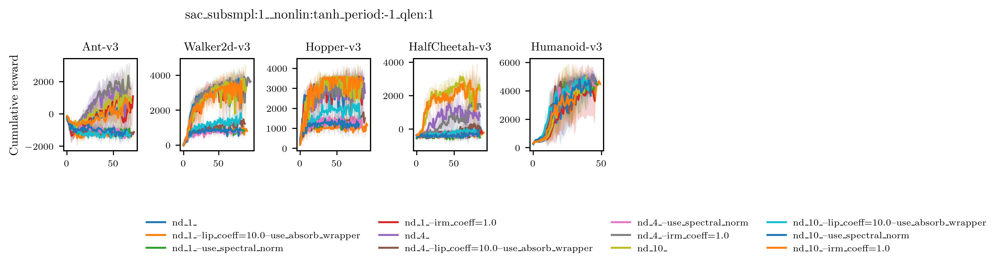

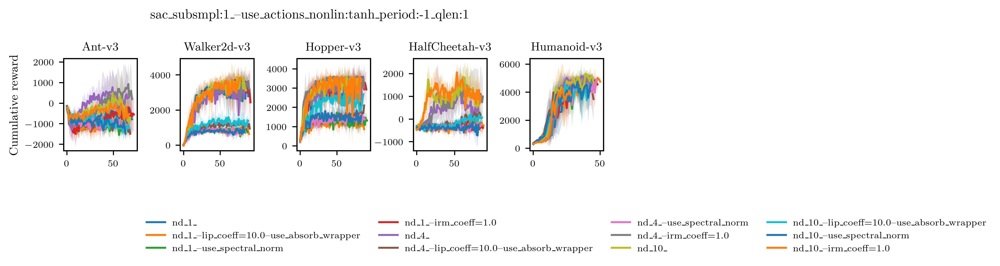

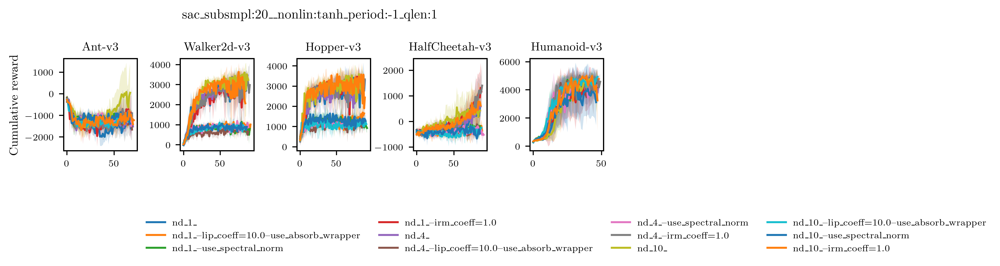

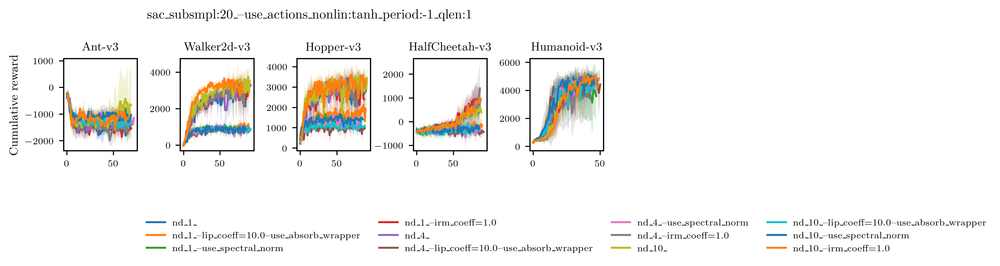

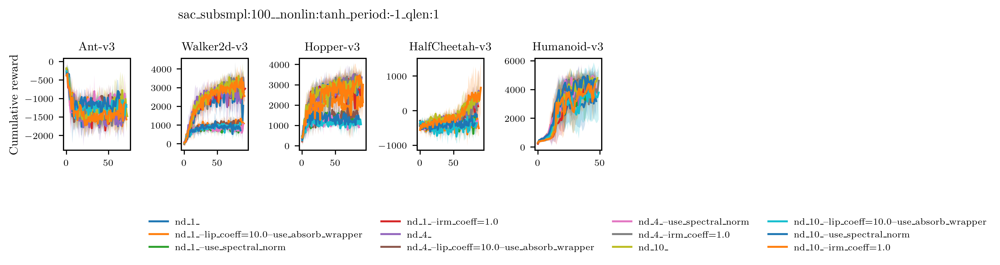

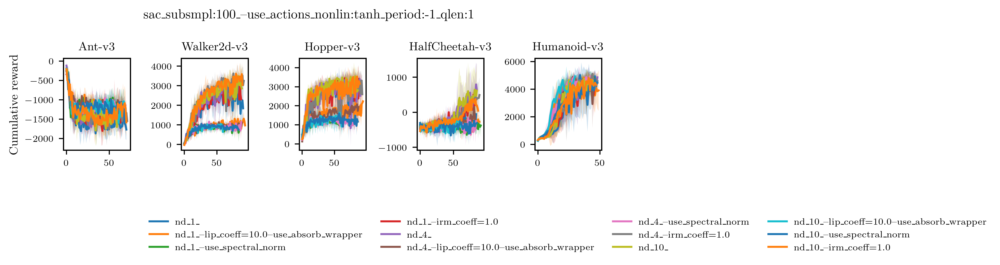

In [17]:
tags = ["charts/episodic_return", "irl/gail_bce_loss", "eval/mu"]

#nonlin="leakyrelu"
#lin = '--linear_proj'
#nob = ''
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']

algos = ['sac']
disc_types = ['airl']
lins = ['', '--lip_coeff=10.0--use_absorb_wrapper', '--use_spectral_norm', '--irm_coeff=1.0']
usenobs = ['', '--use_actions']

qlens = [1]
subsamplings = [1,20,100]
periods = [-1]
disc_nonlins = ['tanh']
print(lins)
n_demos = [1,4,10]

d_mustd_airl = {}
for env in envs:
    d_mustd_airl[env] = {}
    for ss in subsamplings:
        d_mustd_airl[env][f"ss_{ss}"] = {}
        for n_demo in n_demos:
            d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"]  = {}
            for lin in lins:
                d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin]  = {}
                for ua in usenobs:
                    d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua]  = {}
                    for per in periods:
                        d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"]  = {}
                        for qlen in qlens:
                            d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"][f"ql_{qlen}"]  = {}

subsample_plot = 2

for algo in algos:
    for ss in subsamplings:
        for nob in usenobs:
            for per in periods:
                for ql in qlens:
                    for nonlin in disc_nonlins:
                        fig, axs = plt.subplots(1,5, dpi=400, figsize=(figwidth, figwidth/3))
                        fig.tight_layout()                        
                        fig.subplots_adjust(top=0.88)
                        fig.suptitle(f"{algo}_subsmpl:{ss}_{nob}_nonlin:{nonlin}_period:{per}_qlen:{ql}")
                        #plt.style.use('ggplot')
                        #print(lin, nob, nonlin)
                        #plt.title(lin + nob + nonlin)
                        for i, env in enumerate(envs):

                            X_axis = np.arange(len(lins))

                            axs[i].set_title(env)
                            X_index = []
                            Y_mean = []
                            Y_std = []
                            ndem = [1,4,10]
                            #ndem = [10]

                            for j,n_d in enumerate(ndem):
                                Y = []
                                Y_ = []

                                for k,lin in enumerate(lins):
                                    val_list = []
                                    min_len = 1000
                                    df_list = []

                                    for seed in [515, 234, 894, 322, 72]:
                                        df = d_airl[env][seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['airl'][f"per_{per}"][f"ql_{ql}"]
                                        #if not isinstance(ea,dict): # prevents case if we have empty dict
                                        #    df = create_df_from_ea(ea, tags[-1])
                                        df_list.append(df[1])
                                        min_len = min(len(df[1]['Value']), min_len)

                                    for df_ in df_list:
                                        val_list.append(df_['Value'][:min_len])

                                    if len(val_list) > 0:
                                        vals = np.array(val_list)
                                        mu = np.mean(vals,0)[::subsample_plot]
                                        std = np.std(vals,0)[::subsample_plot]
                                        d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][f"per_{per}"][f"ql_{qlen}"] = (mu,std)
                                        lin_label = lin
                                    
                                        axs[i].plot(mu, label=f"nd_{n_d}_{lin_label}")
                                        axs[i].fill_between(np.arange(len(mu)),mu+std, mu-std, alpha=0.2)

                                    else:
                                        Y.append(0)            
                                        Y_.append(0)

                                    #print(Y, Y_)

                                #axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2) 
                                #axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 

                            axs[0].set_ylabel("Cumulative reward")
                            axs[-1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.65), fancybox=False, shadow=False, frameon=False, ncol=4)

                            #plt.legend()
                            plt.tight_layout()

## SWIL

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


['', '--replace_atoms']


/var/folders/g3/q3xhtj8s5bjgf2p8_8yjnr5c0000gn/T/ipykernel_90762/3655538583.py:107: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with

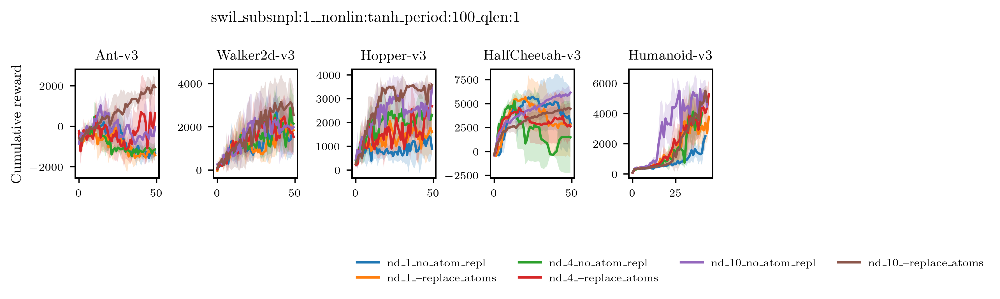

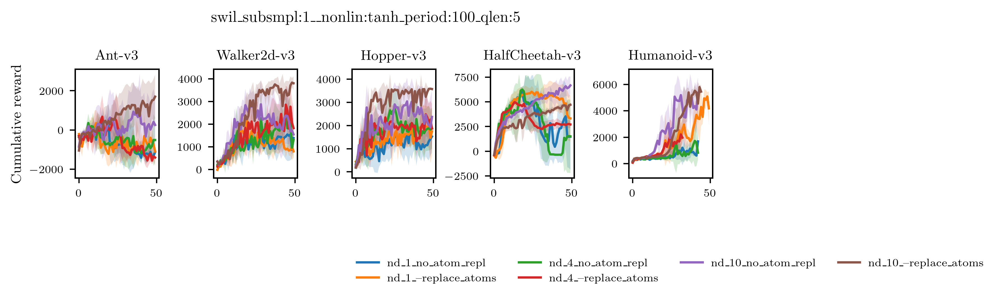

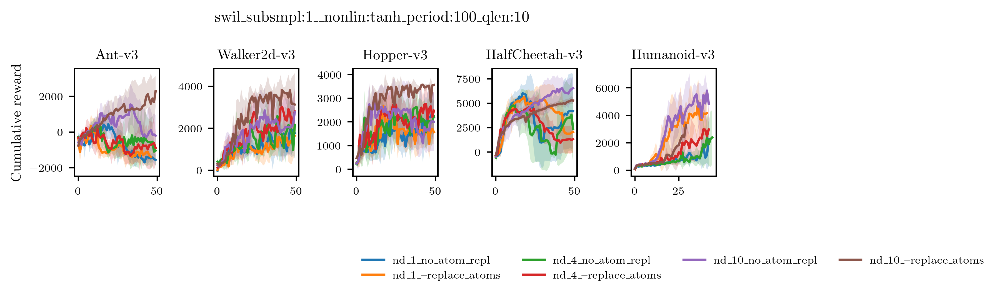

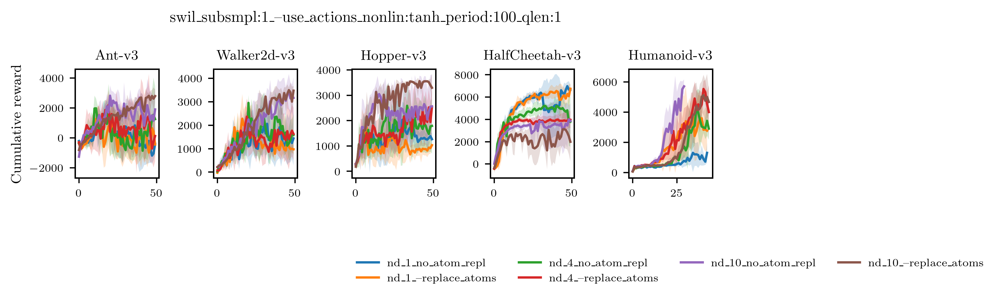

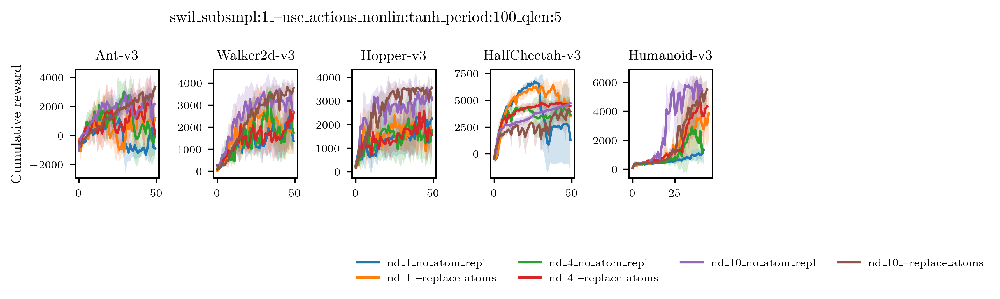

...

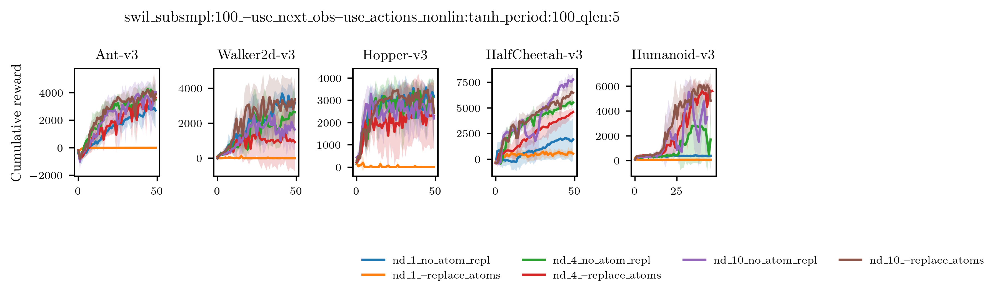

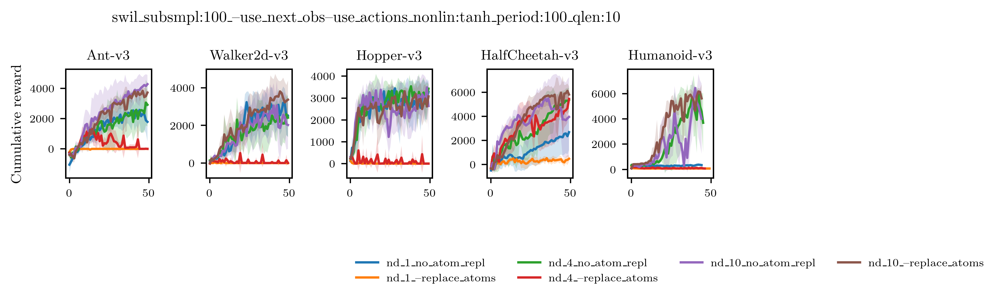

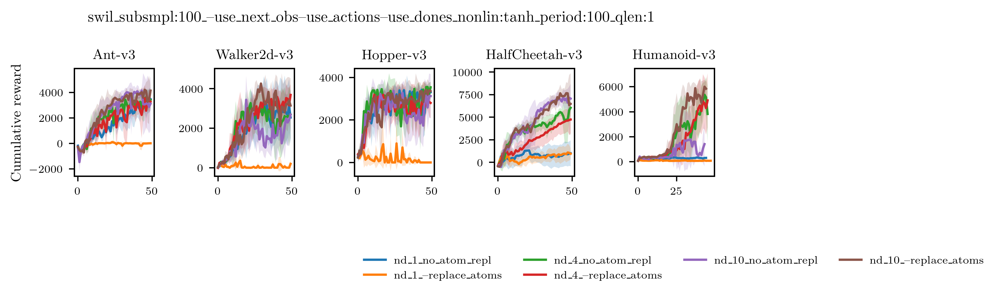

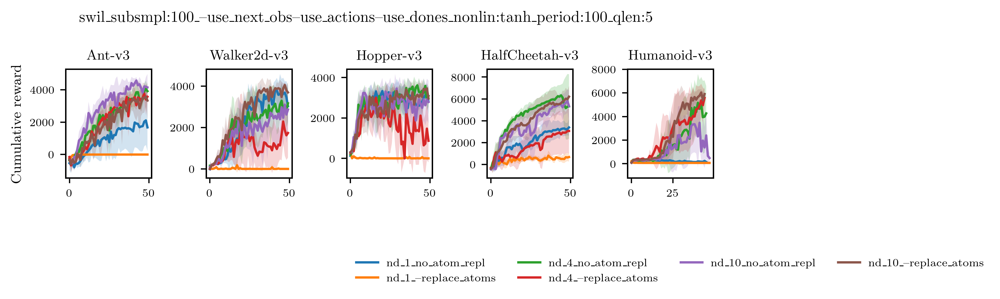

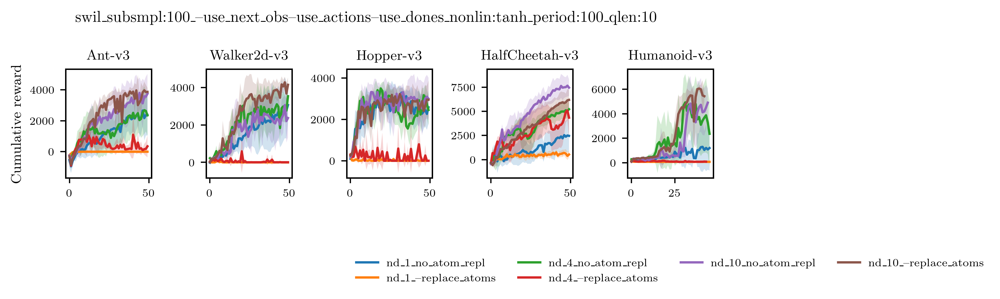

In [18]:
tags = ["charts/episodic_return", "irl/gail_bce_loss", "eval/mu"]

#nonlin="leakyrelu"
#lin = '--linear_proj'
#nob = ''

algos = ['sac']
disc_types = ['swil']
lins = ['', '--replace_atoms']
usenobs = ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']

qlens = [1,5,10]
subsamplings = [1,20,100]
periods = [100]
disc_nonlins = ['tanh']
print(lins)

d_mustd_swil = {}
for env in envs:
    d_mustd_swil[env] = {}
    for ss in subsamplings:
        d_mustd_swil[env][f"ss_{ss}"] = {}
        for n_demo in n_demos:
            d_mustd_swil[env][f"ss_{ss}"][f"nd_{n_demo}"]  = {}
            for lin in lins:
                d_mustd_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][lin]  = {}
                for ua in usenobs:
                    d_mustd_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua]  = {}
                    for per in periods:
                        d_mustd_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"]  = {}
                        for qlen in qlens:
                            d_mustd_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"][f"ql_{qlen}"]  = {}

subsample_plot = 2

for algo in disc_types:
    for ss in subsamplings:
        for nob in usenobs:
            for per in periods:
                for ql in qlens:
                    for nonlin in disc_nonlins:
                        fig, axs = plt.subplots(1,5, dpi=400, figsize=(figwidth, figwidth/3))
                        fig.tight_layout()                        
                        fig.subplots_adjust(top=0.88)
                        fig.suptitle(f"{algo}_subsmpl:{ss}_{nob}_nonlin:{nonlin}_period:{per}_qlen:{ql}")
                        #plt.style.use('ggplot')
                        #print(lin, nob, nonlin)
                        #plt.title(lin + nob + nonlin)
                        for i, env in enumerate(envs):

                            X_axis = np.arange(len(lins))

                            axs[i].set_title(env)
                            X_index = []
                            Y_mean = []
                            Y_std = []
                            ndem = [1,4,10]

                            for j,n_d in enumerate(ndem):
                                Y = []
                                Y_ = []

                                for k,lin in enumerate(lins):
                                    val_list = []
                                    min_len = 1000
                                    df_list = []
                                    for seed in [515, 234, 894, 322, 72]:
                                        df = d_swil[env][seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['swil'][f"per_{per}"][f"ql_{ql}"]
                                        #if not isinstance(ea,dict): # prevents case if we have empty dict
                                        #    df = create_df_from_ea(ea, tags[-1])
                                        df_list.append(df[1])
                                        min_len = min(len(df[1]['Value']), min_len)

                                                                        
                                    for df_ in df_list:
                                        val_list.append(df_['Value'][:min_len])


                                    if len(val_list) > 0:
                                        vals = np.array(val_list)
                                        mu = np.mean(vals,0)[::subsample_plot]
                                        std = np.std(vals,0)[::subsample_plot]
                                        d_mustd_swil[env][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][f"per_{per}"][f"ql_{ql}"] = (mu, std)

                                        (mu,std)
                                        if lin == '':
                                            lin_label = 'no_atom_repl'
                                        else:
                                            lin_label = lin
                                    
                                        axs[i].plot(mu, label=f"nd_{n_d}_{lin_label}")
                                        axs[i].fill_between(np.arange(len(mu)),mu+std, mu-std, alpha=0.2)

                                    else:
                                        Y.append(0)            
                                        Y_.append(0)

                                    #print(Y, Y_)

                                #axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2) 
                                #axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 

                            axs[0].set_ylabel("Cumulative reward")
                            axs[-1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.65), fancybox=False, shadow=False, frameon=False, ncol=4)

                            #plt.legend()
                            plt.tight_layout()

## Plot to finally combine it all...

In [21]:
def plot_comp(d_ms_swil, d_ms_gail, d_ms_airl, n_demo, swil_ql, ss, subsample_plot=1, savefig=False):
    envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
    env_exp = [5150, 4050, 3607, 8900, 6249]
    NUM_COLORS = 5
    #cm = plt.get_cmap('gist_rainbow')
    #cm = sns.color_palette("tab10", as_cmap=True)
    cm =sns.color_palette("icefire", as_cmap=True)

    lw=1
    
    fig, axs = plt.subplots(1,5, dpi=400, figsize=(figwidth,figwidth/4))
    fig.suptitle(f"ss:{ss}_ql:{swil_ql}_nd:{n_demo}")
    fig.subplots_adjust(top=0.88)

    for i, env in enumerate(envs):
        axs[i].set_title(f"{env}")
        axs[i].set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])
        axs[i].axhline(env_exp[i], c='r', linestyle='dotted', alpha=0.5)

        for lin_gail in ['', '--lip_coeff=1.0', '--use_spectral_norm']:
        #for lin_gail in ['','--use_spectral_norm']:
            mu, std = d_ms_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin_gail][''][f"per_-1"][f"ql_1"]
            mu, std = smooth_mu_std(mu,std)
            mu = mu[::subsample_plot]
            std = std[::subsample_plot]
            #x = np.arange(len(mu))*1e6/len(mu)
            x = np.arange(len(mu))/len(mu)

            #axs[i].plot(x,mu, label=f"gail_{lin_gail}", marker='+', linewidth=3)
            #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)
            mu_, std_ = d_ms_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin_gail]['--use_actions'][f"per_-1"][f"ql_1"]
            mu_, std_ = smooth_mu_std(mu_,std_)
            mu_ = mu_[::subsample_plot]
            std_ = std_[::subsample_plot]
            #x_ = np.arange(len(mu_))*1e6/len(mu_)
            x_ = np.arange(len(mu_))/len(mu_)

            if 'lip_c' in lin_gail:
                label = 'DAC'
            elif 'spectral_norm' in lin_gail:
                label = 'GAIL_SN'
            else:
                label = 'GAIL'
            
            if np.mean(mu_) > np.mean(mu):
                #axs[i].plot(x_, mu_, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                axs[i].plot(x_, mu_, label=label, marker='+', linewidth=lw)
                axs[i].fill_between(x_,mu_+std_, mu_-std_, alpha=0.2)  
            else:
                #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                axs[i].plot(x, mu, label=label, marker='+', linewidth=lw)
                axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)                      


        for nob_swil in ['--use_next_obs--use_actions']: #, '--use_next_obs--use_actions--use_dones']:        
        #for nob_swil in ['--use_next_obs--use_actions--use_dones']:        
            mu, std = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][''][nob_swil][f"per_100"][f"ql_{swil_ql}"]
            mu, std = smooth_mu_std(mu,std)
            mu = mu[::subsample_plot]
            std = std[::subsample_plot]
            
            #x = np.arange(len(mu))*1e6/len(mu)
            x = np.arange(len(mu))/len(mu)

            #label = f"swil_{nob_swil}_ra"
            label = "SWIL_RA"
            #axs[i].plot(x, mu, label=f"swil_{nob_swil}", marker='o', linewidth=3)
            #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)

            mu_, std_ = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_demo}"]['--replace_atoms'][nob_swil][f"per_100"][f"ql_{swil_ql}"]
            mu_, std_ = smooth_mu_std(mu_,std_)
            mu_ = mu_[::subsample_plot]
            std_ = std_[::subsample_plot]
            # rescale
            #x_ = np.arange(len(mu_))*1e6/len(mu_)
            x_ = np.arange(len(mu_))/len(mu_)
            
            #label = f"swil_{nob_swil}_ra"
            label = "SWIL_RA"
            
            if np.mean(mu_) > np.mean(mu):
                #axs[i].plot(x_, mu_, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                axs[i].plot(x_, mu_, label=f"SWIL", marker='.', linewidth=lw)
                axs[i].fill_between(x_,mu_+std_, mu_-std_, alpha=0.2)  
            else:
                #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                axs[i].plot(x, mu, label=f"SWIL", marker='.', linewidth=lw)
                axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)                      

            #axs[i].plot(x, mu, label=label, marker='o', linewidth=3)
            #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)    

        #axs[i].set_xticks(['0','1M'])
        #axs[i].axis('equal')
        #axs[i].set_xlim(0,20)
    axs[0].set_ylabel("Cumulative reward")
    
    #axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
    fig.subplots_adjust(bottom=0.3, wspace=0.33)
    #plt.tight_layout()

    if n_demo == 10:
        axs[2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.2),fancybox=False, shadow=False, frameon=False, ncol=5)
    #plt.legend(loc="lower left", ncol=len(df.columns))
    if savefig:
        plt.savefig(f"plots/ss{ss}_ql{swil_ql}_nd{n_demo}.pdf", dpi=400, bbox_inches='tight')
    

### Main plot

In [39]:
def smooth_mu_std(mu, std, N=6):
    mu_s = np.convolve(mu, np.ones(N)/N, mode='valid')
    std_s = np.convolve(std, np.ones(N)/N, mode='valid')
    
    return mu_s, std_s

###
def plot_comp_2(d_ms_swil, d_ms_gail, d_ms_airl, n_demos, swil_ql, sss, subsample_plot=1, savefig=None):

    envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
    env_exp = [5150, 4050, 3607, 8900, 6249]

    n_demos = [1,4,10]
    sss = [1]
    subsample_plot = 1
    NUM_COLORS = 6
    #cm = plt.get_cmap('gist_rainbow')
    #cm = sns.color_palette("tab10", as_cmap=True)
    cm =sns.color_palette("icefire", as_cmap=True)
    from itertools import cycle

    linestyle_tuple = [
         ('solid', 'solid'), 
         ('dashdot', 'dashdot'),
         ('dotted',                (0, (1, 1))),
         ('densely dotted',        (0, (1, 1))),
         ('densely dashed',        (0, (5, 1))),
         ('dashdotted',            (0, (3, 5, 1, 5))),
         ('densely dashdotted',    (0, (3, 1, 1, 1))),
         ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
         ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

    linecycler = cycle(linestyle_tuple[:NUM_COLORS])

    text_width = 5.8
    text_height = 9.0
    fig,ax = plt.subplots(3,5, dpi=400, figsize=[text_width, 2.6])
    #fig.tight_layout(w_pad=1, h_pad=1)
    fig.tight_layout(h_pad=-0.5,w_pad=0.4)
    lw = 1

    for ss in sss:
        for i, n_d in enumerate(n_demos):
            #fig, ax = plt.subplots(1,5,figsize=(24,4))
            #fig.suptitle(f"ss:{ss}_nd:{n_d}")

            for j, env in enumerate(envs):
                # plot gail
                ax[i,j].set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])

                if 'Walker' in env:
                    ax[0,j].set_title('Walker2D-v3')
                else:
                    ax[0,j].set_title(env)
                #if j > 0:
                    #remove_yticks(ax[i,j])
                    #ax[i,j].spines[['left']].set_visible(False)

                ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=1.0)

                if i < 2:
                    ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
                    remove_xticks(ax[i,j])
                    ax[i,j].axvline(0.5, alpha=0.3, linestyle=':', color='gray', linewidth=0.8)



                ax[i,j].spines[['top' , 'right']].set_visible(False)
                ax[i,j].spines['left'].set_position(('axes', -0.05))
                ax[i,j].spines['bottom'].set_position(('axes', -0.08))

                ax[i,j].grid(alpha=0.5, linestyle=':')

                # set env specific limits
                ax[i,0].set_ylim(-2000, 5200)
                ax[i,0].set_yticks([-2000, 1600, 5200],['-2k','1.6k','5.2k'])
                ax[i,1].set_ylim(0, 4500)
                ax[i,1].set_yticks([0, 2300, 4600],['0','2.3k','4.6k'])
                ax[i,2].set_ylim(0, 4000)
                ax[i,2].set_yticks([0, 2000, 4000],['0','2k','4k'])            
                ax[i,3].set_ylim(-1000, 9000)
                ax[i,3].set_yticks([-1000, 4000, 9000],['-1k','4k','9k'])                        
                ax[i,4].set_ylim(0, 7000)
                ax[i,4].set_yticks([0, 3500, 7000],['0','3.5k','7k'])                                          
                ax[2,j].set_xlim(0,1.0)
                ax[2,j].set_xticks([0, 0.5, 1.0])


                for lin_gail in ['', '--lip_coeff=1.0', '--use_spectral_norm']:
                #for lin_gail in ['','--use_spectral_norm']:
                    mu, std = d_ms_gail[env][f"ss_{ss}"][f"nd_{n_d}"][lin_gail][''][f"per_-1"][f"ql_1"]
                    mu, std = smooth_mu_std(mu,std)
                    mu = mu[::subsample_plot]
                    std = std[::subsample_plot]
                    #x = np.arange(len(mu))*1e6/len(mu)
                    x = np.arange(len(mu))/len(mu)

                    #axs[i].plot(x,mu, label=f"gail_{lin_gail}", marker='+', linewidth=3)
                    #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)
                    mu_, std_ = d_ms_gail[env][f"ss_{ss}"][f"nd_{n_d}"][lin_gail]['--use_actions'][f"per_-1"][f"ql_1"]
                    mu_, std_ = smooth_mu_std(mu_,std_)
                    mu_ = mu_[::subsample_plot]
                    std_ = std_[::subsample_plot]
                    #x_ = np.arange(len(mu_))*1e6/len(mu_)
                    x_ = np.arange(len(mu_))/len(mu_)

                    if 'lip_c' in lin_gail:
                        label = 'DAC'
                    elif 'spectral_norm' in lin_gail:
                        label = 'GAIL (SN)'
                    else:
                        label = 'GAIL'

                    if np.mean(mu_) > np.mean(mu):
                        #axs[i].plot(x_, mu_, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                        ax[i,j].plot(x_, mu_, label=label, linewidth=lw)
                        ax[i,j].fill_between(x_,mu_+std_, mu_-std_, alpha=0.2)  
                    else:
                        #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                        ax[i,j].plot(x, mu, label=label, linewidth=lw)
                        ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.2)                      

                for lin_airl in ['']:
                #for lin_gail in ['','--use_spectral_norm']:
                    mu, std = d_ms_airl[env][f"ss_{ss}"][f"nd_{n_d}"][lin_gail][''][f"per_-1"][f"ql_1"]
                    mu, std = smooth_mu_std(mu,std)
                    mu = mu[::subsample_plot]
                    std = std[::subsample_plot]
                    #x = np.arange(len(mu))*1e6/len(mu)
                    x = np.arange(len(mu))/len(mu)

                    #axs[i].plot(x,mu, label=f"gail_{lin_gail}", marker='+', linewidth=3)
                    #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)
                    mu_, std_ = d_ms_airl[env][f"ss_{ss}"][f"nd_{n_d}"][lin_gail]['--use_actions'][f"per_-1"][f"ql_1"]
                    mu_, std_ = smooth_mu_std(mu_,std_)
                    mu_ = mu_[::subsample_plot]
                    std_ = std_[::subsample_plot]
                    #x_ = np.arange(len(mu_))*1e6/len(mu_)
                    x_ = np.arange(len(mu_))/len(mu_)

                    label = 'AIRL'

                    if np.mean(mu_) > np.mean(mu):
                        #axs[i].plot(x_, mu_, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                        ax[i,j].plot(x_, mu_, label=label, linewidth=lw)
                        ax[i,j].fill_between(x_,mu_+std_, mu_-std_, alpha=0.2)  
                    else:
                        #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                        ax[i,j].plot(x, mu, label=label, linewidth=lw)
                        ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.2)        
                        
                for nob_swil in ['--use_next_obs--use_actions']: #, '--use_next_obs--use_actions--use_dones']:        
                #for nob_swil in ['--use_next_obs--use_actions--use_dones']:        
                    mu, std = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_d}"][''][nob_swil][f"per_100"][f"ql_{1}"]
                    mu, std = smooth_mu_std(mu,std)
                    mu = mu[::subsample_plot]
                    std = std[::subsample_plot]

                    #x = np.arange(len(mu))*1e6/len(mu)
                    x = np.arange(len(mu))/len(mu)

                    #label = f"swil_{nob_swil}_ra"
                    label = "SWIL_RA"
                    #axs[i].plot(x, mu, label=f"swil_{nob_swil}", marker='o', linewidth=3)
                    #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)

                    mu_, std_ = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_d}"]['--replace_atoms'][nob_swil][f"per_100"][f"ql_{1}"]
                    mu_, std_ = smooth_mu_std(mu_,std_)
                    mu_ = mu_[::subsample_plot]
                    std_ = std_[::subsample_plot]
                    # rescale
                    #x_ = np.arange(len(mu_))*1e6/len(mu_)
                    x_ = np.arange(len(mu_))/len(mu_)

                    #label = f"swil_{nob_swil}_ra"
                    label = "SWIL_RA"

                    if np.mean(mu_) > np.mean(mu):
                        #axs[i].plot(x_, mu_, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                        ax[i,j].plot(x_, mu_, label=f"SWIL (QL1)", linewidth=lw)
                        ax[i,j].fill_between(x_,mu_+std_, mu_-std_, alpha=0.2)  
                    else:
                        #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                        ax[i,j].plot(x, mu, label=f"SWIL (QL1)", linewidth=lw)
                        ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.2)        
                        
                for nob_swil in ['--use_next_obs--use_actions']: #, '--use_next_obs--use_actions--use_dones']:        
                #for nob_swil in ['--use_next_obs--use_actions--use_dones']:        
                    mu, std = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_d}"][''][nob_swil][f"per_100"][f"ql_{swil_ql}"]
                    mu, std = smooth_mu_std(mu,std)
                    mu = mu[::subsample_plot]
                    std = std[::subsample_plot]

                    #x = np.arange(len(mu))*1e6/len(mu)
                    x = np.arange(len(mu))/len(mu)

                    #label = f"swil_{nob_swil}_ra"
                    label = "SWIL_RA"
                    #axs[i].plot(x, mu, label=f"swil_{nob_swil}", marker='o', linewidth=3)
                    #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)

                    mu_, std_ = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_d}"]['--replace_atoms'][nob_swil][f"per_100"][f"ql_{swil_ql}"]
                    mu_, std_ = smooth_mu_std(mu_,std_)
                    mu_ = mu_[::subsample_plot]
                    std_ = std_[::subsample_plot]
                    # rescale
                    #x_ = np.arange(len(mu_))*1e6/len(mu_)
                    x_ = np.arange(len(mu_))/len(mu_)

                    #label = f"swil_{nob_swil}_ra"
                    label = "SWIL_RA"

                    if np.mean(mu_) > np.mean(mu):
                        #axs[i].plot(x_, mu_, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                        ax[i,j].plot(x_, mu_, label=f"SWIL (QL10)", linewidth=lw)
                        ax[i,j].fill_between(x_,mu_+std_, mu_-std_, alpha=0.2)  
                    else:
                        #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                        ax[i,j].plot(x, mu, label=f"SWIL (QL10)", linewidth=lw)
                        ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.2)    
                        
 

            ax[2,2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.65), fancybox=False, shadow=False, frameon=False, ncol=8, columnspacing=1.0)
            ax[2,2].set_xlabel('M. Timesteps')
            ax[1,0].set_ylabel('Episode reward')
            ax[0,-1].yaxis.set_label_position("right")
            ax[1,-1].yaxis.set_label_position("right")
            ax[2,-1].yaxis.set_label_position("right") 
            ax[0,-1].set_ylabel("1 traj.")
            ax[1,-1].set_ylabel("4 traj.")
            ax[2,-1].set_ylabel("10 traj.")


    #fig.tight_layout(w_pad=1, h_pad=1)
    #plt.tight_layout()
    if savefig is not None:
        fig.savefig(f"{savefig}.pdf", bbox_inches='tight', pad_inches=0.01)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


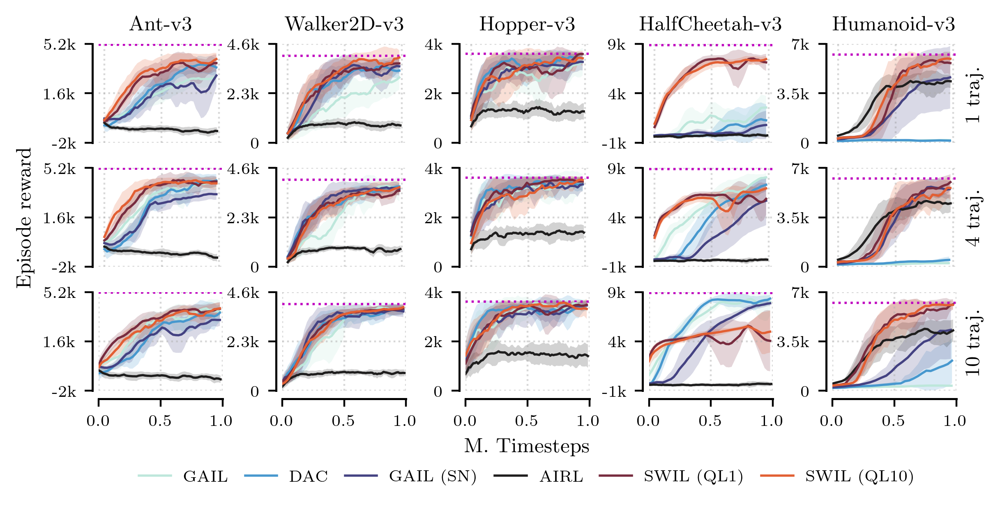

In [40]:
plot_comp_2(d_mustd_swil, d_mustd_gail, d_mustd_airl, n_demos=[1,4,10], swil_ql=10, sss=[1], subsample_plot=1, savefig="main_plot_k")

### Ablation study 1: data sparse setting (plot)

In [41]:
def plot_comp_ss(env, nob_swils, swil_ql_, d_ms_swil, d_ms_gail, n_demo, subsample_plot=1, savefig=None):
    envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
    env_exp = [5150, 4050, 3607, 8900, 6249]
    subsamplings = [1,20,100]
    NUM_COLORS = 20
    #cm = plt.get_cmap('gist_rainbow')
    #cm = sns.color_palette("tab10", as_cmap=True)
    cm =sns.color_palette("mako", as_cmap=True)

    fig, axs = plt.subplots(1,len(subsamplings), figsize=(20,6))
    #fig.suptitle(f"ss:{ss}_ql:{swil_ql}_nd:{n_demo}")
    for i, ss in enumerate(subsamplings):
        axs[i].set_title(f"{env}_ss:{ss}_nd:{n_demo}")
        axs[i].set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])
        axs[i].axhline(env_exp[envs.index(env)], c='k')

        #for lin_gail in ['', '--irm_coeff=1.0', '--lip_coeff=1.0', '--use_spectral_norm', '--use_absorb_wrapper']:
        for lin_gail in ['', '--lip_coeff=1.0', '--use_spectral_norm']:
            mu, std = d_ms_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin_gail][''][f"per_-1"][f"ql_1"]
            mu, std = smooth_mu_std(mu,std)
            mu = mu[::subsample_plot]
            std = std[::subsample_plot]
            x = np.arange(len(mu))*1e6/len(mu)

            #axs[i].plot(x,mu, label=f"gail_{lin_gail}", marker='+')
            #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)
            mu, std = d_ms_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin_gail]['--use_actions'][f"per_-1"][f"ql_1"]
            mu, std = smooth_mu_std(mu,std)

            mu = mu[::subsample_plot]
            std = std[::subsample_plot]
            x = np.arange(len(mu))*1e6/len(mu)

            axs[i].plot(x, mu, label=f"gail_{lin_gail}_ua", marker='D')
            axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)

        #for nob_swil in ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']:        
        #    for swil_ql in [1,5,10]:
        #for nob_swil in ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']:       
        for nob_swil in nob_swils:        
            for swil_ql in [swil_ql_]:
            #for nob_swil in ['--use_next_obs--use_actions--use_dones']:        
                mu, std = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][''][nob_swil][f"per_100"][f"ql_{swil_ql}"]
                mu, std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))*1e6/len(mu)

                #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)

                mu_, std_ = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_demo}"]['--replace_atoms'][nob_swil][f"per_100"][f"ql_{swil_ql}"]
                mu_, std_ = smooth_mu_std(mu_,std_)
                mu_ = mu_[::subsample_plot]
                std_ = std_[::subsample_plot]
                # rescale
                x_ = np.arange(len(mu_))*1e6/len(mu_)
                
                if np.mean(mu_) > np.mean(mu):
                    #axs[i].plot(x_, mu_, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                    axs[i].plot(x_, mu_, label=f"swil_ra", marker='o')
                    axs[i].fill_between(x_,mu_+std_, mu_-std_, alpha=0.2)  
                else:
                    #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                    axs[i].plot(x, mu, label=f"swil", marker='o')
                    axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)                      

        #axs[i].set_xticks(['0','1M'])
        #axs[i].axis('equal')
        #axs[i].set_xlim(0,20)
    axs[0].set_ylabel("Episode reward")
    
    #axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
    fig.subplots_adjust(bottom=0.3, wspace=0.33)
    #plt.tight_layout()

    axs[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.2),fancybox=False, shadow=False, ncol=3)
    #plt.legend(loc="lower left", ncol=len(df.columns))
    if savefig is not None:
        plt.savefig(f"plots/{savefig}.png", dpi=300, bbox_inches='tight')



In [121]:
def plot_comp_ss_joint(envs, nob_swils, swil_ql_, d_ms_swil, d_ms_gail, d_ms_airl, n_demo, subsample_plot=1, savefig=None):
    
    #font_size = 9
    #matplotlib.rcParams['font.size'] = font_size
    #matplotlib.rcParams["font.weight"] = "bold"
    #matplotlib.rcParams['text.usetex'] = True
    #matplotlib.rcParams['axes.labelsize'] = font_size
    #matplotlib.rcParams['axes.titlesize'] = 10
    #matplotlib.rcParams['legend.fontsize'] = font_size
    #matplotlib.rcParams['xtick.labelsize'] = font_size
    #matplotlib.rcParams['ytick.labelsize'] = font_size
    from matplotlib.lines import Line2D
    from matplotlib.gridspec import GridSpec
    fs_m1 = 7  # for figure ticks
    fs = 9  # for regular figure text
    fs_p1 = 10  # figure titles

    axes_lw = 0.8

    matplotlib.rc('font', size=fs)          # controls default text sizes
    matplotlib.rc('axes', titlesize=fs)     # fontsize of the axes title
    matplotlib.rc('axes', labelsize=fs)    # fontsize of the x and y labels
    matplotlib.rc('axes', linewidth=axes_lw)    # fontsize of the x and y labels
    matplotlib.rc('xtick', labelsize=fs_m1)    # fontsize of the tick labels
    matplotlib.rc('ytick', labelsize=fs_m1)    # fontsize of the tick labels
    matplotlib.rc('legend', fontsize=fs_m1)    # legend fontsize
    matplotlib.rc('figure', titlesize=fs_p1)  # fontsize of the figure title

    matplotlib.rc('font', **{'family': 'serif', 'serif': ['Times New Roman']})

    matplotlib.rc('text', usetex=True)

    plt.rcParams.update({'text.latex.preamble': r'\usepackage{amsfonts}'})

    def remove_xticks(ax):
        for tick in ax.xaxis.get_major_ticks():
            tick.tick1line.set_visible(False)
            tick.tick2line.set_visible(False)
        ax.xaxis.set_tick_params(which='minor', bottom=False, top=False)
        ax.xaxis.set_tick_params(which='major', bottom=False, top=False)
        ax.set_xticklabels([])

    def remove_yticks(ax):
        for tick in ax.yaxis.get_major_ticks():
            tick.tick1line.set_visible(False)
            tick.tick2line.set_visible(False)
        ax.yaxis.set_tick_params(which='minor', left=False)
        ax.set_yticklabels([])

    
    name_map_d = {'':'$\mathcal{S}$', '--use_actions':r'$\mathcal{S}\times\mathcal{A}$', '--use_next_obs--use_actions':r'$\mathcal{S}\times\mathcal{A}\times\mathcal{S}$', '--use_next_obs--use_actions--use_dones':'SASD'}

    env_exp = [5150, 6249]
    subsamplings = [1,20,100]
    NUM_COLORS = 7
    #cm = plt.get_cmap('gist_rainbow')
    #cm = sns.color_palette("tab10", as_cmap=True)
    cm =sns.color_palette("icefire", as_cmap=True)

    fig, axs = plt.subplots(1,len(subsamplings)*len(envs), dpi=400,figsize=(5.8,1.1))
    #fig.tight_layout()
    fig.tight_layout(w_pad=-1.5, h_pad=1)
    #fig.suptitle(f"ss:{ss}_ql:{swil_ql}_nd:{n_demo}")
    
    exps = {'Ant:1':1 ,'Ant:20':20, 'Ant:100':100, 'Humanoid:1':1, 'Humanoid:20':20, 'Humanoid:100':100}
    xlabels = ['$\zeta=1$','$\zeta=20$','$\zeta=100$','$\zeta=1$','$\zeta=20$','$\zeta=100$']

    
    for i, exp in enumerate(exps.keys()):
        if 'Ant' in exp:
            env = 'Ant-v3'
        else:
            env = 'Humanoid-v3'
        #matplotlib.rcParams['ytick.labelsize'] = font_size
        #matplotlib.rcParams['axes.labelsize'] = 32
        #matplotlib.rcParams['axes.labelsize'] = 32

        #axs[i].set_title(exp)
        axs[1].set_title('Ant')
        axs[4].set_title('Humanoid')

        axs[i].set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])
        #axs[i].axhline(env_exp[envs.index(env)], c='r', linestyle='dotted', alpha=0.5)
        axs[i].axhline(env_exp[envs.index(env)], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=1.0)

        ss = exps[exp]

        axs[i].spines[['top' , 'right']].set_visible(False)
        shift = 0.02
        if i%3 != 0:
            print(i)
            axs[i].spines[['left']].set_visible(False)    
            ax_pos = axs[i].get_position()
            
            if i<3:
                ax_pos.x0 -= shift
                ax_pos.x1 -= shift
            else:
                ax_pos.x0 += shift
                ax_pos.x1 += shift

            print(ax_pos)
            axs[i].set_position(ax_pos)
        else:
            if i > 0:
                ax_pos = axs[i].get_position()
                ax_pos.x0 += shift
                ax_pos.x1 += shift
                axs[i].set_position(ax_pos)
            else:
                ax_pos = axs[i].get_position()
                ax_pos.x0 -= shift
                ax_pos.x1 -= shift
                axs[i].set_position(ax_pos)  



        axs[i].spines['left'].set_position(('axes', -0.05))
        axs[i].spines['bottom'].set_position(('axes', -0.08))

        axs[i].grid(alpha=0.4, linestyle=':')

        # set env specific limits

        if 'Humanoid' in exp:
            axs[i].set_ylim(0, 7000)
            if i == 3:
                axs[i].set_yticks([0, 3500, 7000],['0','3.5k','7k'])                                          
            else:
                #axs[i].set_yticks([-0, 3500, 7000],['','',''])
                axs[i].set_yticks([])
                axs[i].axvline(3500, alpha=0.3, linestyle=':', color='gray', linewidth=0.8)
        else:
            axs[i].set_ylim(-2000, 5200)
            if i == 0:
                axs[i].set_yticks([-2000, 1600, 5200],['-2k','1.6k','5.2k'])
            else:
                #axs[i].set_yticks([-2000, 1600, 5200],['','',''])
                axs[i].set_yticks([])
                axs[i].axvline(1600, alpha=0.3, linestyle=':', color='gray', linewidth=0.8)


        axs[i].set_xlim(0,1.0)
        axs[i].set_xticks([0, 0.5, 1.0])
        axs[i].set_xlabel(xlabels[i])

        #for lin_gail in ['', '--irm_coeff=1.0', '--lip_coeff=1.0', '--use_spectral_norm', '--use_absorb_wrapper']:
        for lin_gail in ['', '--lip_coeff=1.0', '--use_spectral_norm']:
            mu, std = d_ms_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin_gail][''][f"per_-1"][f"ql_1"]
            mu, std = smooth_mu_std(mu,std)
            mu = mu[::subsample_plot]
            std = std[::subsample_plot]
            x = np.arange(len(mu))/len(mu)

            #axs[i].plot(x,mu, label=f"gail_{lin_gail}", marker='+')
            #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)
            mu, std = d_ms_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin_gail]['--use_actions'][f"per_-1"][f"ql_1"]
            mu, std = smooth_mu_std(mu,std)

            mu = mu[::subsample_plot]
            std = std[::subsample_plot]
            x = np.arange(len(mu))/len(mu)

            if 'lip_c' in lin_gail:
                label = 'DAC'
            elif 'spectral_norm' in lin_gail:
                label = 'GAIL (SN)'
            else:
                label = 'GAIL'
            
            axs[i].plot(x, mu, label=label, linewidth=1)
            axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)
            
        for lin_airl in ['']: #,'--lip_coeff=10.0--use_absorb_wrapper']:
        #for lin_gail in ['','--use_spectral_norm']:
            mu, std = d_ms_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin_airl][''][f"per_-1"][f"ql_1"]
            mu, std = smooth_mu_std(mu,std)
            mu = mu[::subsample_plot]
            std = std[::subsample_plot]
            x = np.arange(len(mu))/len(mu)
            #label=f"{label}_{lin_airl}"
            label = 'AIRL'
            axs[i].plot(x, mu, label=label, linewidth=1)
            axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)
   

        #for nob_swil in ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']:        
        #    for swil_ql in [1,5,10]:
        #for nob_swil in ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']:       
        for nob_swil in nob_swils:        
            for swil_ql in [swil_ql_]:
            #for nob_swil in ['--use_next_obs--use_actions--use_dones']:        
                mu, std = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][''][nob_swil][f"per_100"][f"ql_{swil_ql}"]
                mu, std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)

                #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)

                mu_, std_ = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_demo}"]['--replace_atoms'][nob_swil][f"per_100"][f"ql_{swil_ql}"]
                mu_, std_ = smooth_mu_std(mu_,std_)
                mu_ = mu_[::subsample_plot]
                std_ = std_[::subsample_plot]
                # rescale
                x_ = np.arange(len(mu_))/len(mu_)
                
                if np.mean(mu_) > np.mean(mu):
                    #axs[i].plot(x_, mu_, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                    axs[i].plot(x_, mu_, label=f"SWIL ({name_map_d[nob_swil]})", linewidth=1)
                    axs[i].fill_between(x_,mu_+std_, mu_-std_, alpha=0.2)  
                else:
                    #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                    axs[i].plot(x, mu, label=f"SWIL ({name_map_d[nob_swil]})", linewidth=1)
                    axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)                      

        #axs[i].set_xticks(['0','1M'])
        #axs[i].axis('equal')
        #axs[i].set_xlim(0,20)

    axs[0].set_ylabel("Episode reward")
    #axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
    #fig.subplots_adjust(bottom=0.3, wspace=0.33)
    #plt.tight_layout()
    #matplotlib.rcParams['legend.fontsize'] = 24
    axs[2].legend(loc='upper center', bbox_to_anchor=(1.0, -0.8), fancybox=False, shadow=False, frameon=False, ncol=7, columnspacing=1.0)
    #plt.legend(loc="lower left", ncol=len(df.columns))
    fig.text(0.5, -0.15, 'M. Timesteps', ha='center', va='center')

    #plt.tight_layout()
    if savefig is not None:
        plt.savefig(f"plots/{savefig}.pdf", dpi=400, bbox_inches='tight')



1
Bbox(x0=0.2077534479948912, y0=0.28938071230773643, x1=0.3303010030375979, y1=0.8466986223180493)
2
Bbox(x0=0.36127356293741986, y0=0.28938071230773643, x1=0.4838211179801266, y1=0.8466986223180493)
4
Bbox(x0=0.7083137928224773, y0=0.28938071230773643, x1=0.8308613478651841, y1=0.8466986223180493)
5
Bbox(x0=0.861833907765006, y0=0.28938071230773643, x1=0.9843814628077128, y1=0.8466986223180493)


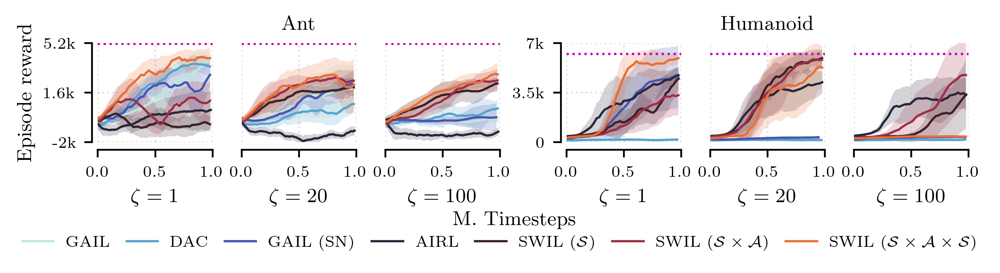

In [122]:
plot_comp_ss_joint(['Ant-v3', 'Humanoid-v3'], ['', '--use_actions','--use_next_obs--use_actions'], 5, d_mustd_swil, d_mustd_gail, d_mustd_airl, 1, savefig="subsampling_plot_")

In [ ]:
for env in ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']:
    plot_comp_ss(env, d_mustd_swil, d_mustd_gail, 1)
    plot_comp_ss(env, d_mustd_swil, d_mustd_gail, 4)
    plot_comp_ss(env, d_mustd_swil, d_mustd_gail, 10)

In [ ]:
plot_comp_ss('Humanoid-v3', ['', '--use_actions','--use_next_obs--use_actions--use_dones'], 5, d_mustd_swil, d_mustd_gail, 1, savefig='ss_comp_humanoid_nd1')
plot_comp_ss('Humanoid-v3', ['', '--use_actions','--use_next_obs--use_actions--use_dones'], 10, d_mustd_swil, d_mustd_gail, 4, savefig='ss_comp_humanoid_nd4')
plot_comp_ss('Humanoid-v3', ['', '--use_actions','--use_next_obs--use_actions--use_dones'], 10, d_mustd_swil, d_mustd_gail, 10, savefig='ss_comp_humanoid_nd10')

### Ablation study 2 (histogram plot)
for Humanoid and Ant across all n_demos
Variations: measurable space (get sxs results)? queue length? Replace atoms

In [ ]:
tags = ["charts/episodic_return", "irl/gail_bce_loss", "eval/mu"]

#nonlin="leakyrelu"
#lin = '--linear_proj'
#nob = ''
sns.set_style(style='white')

algos = ['sac']
disc_types = ['swil']
lins = ['', '--replace_atoms']
usenobs = ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']

qlens = [1,5,10]
#subsamplings = [1,20,100]
subsamplings = [20]
periods = [100]
disc_nonlins = ['tanh']
print(lins)

envs_ = ['Ant-v3', 'Humanoid-v3']
variants = []
for ql in qlens:
    for l in lins:
        for nob in usenobs:
            variants.append(f"{l}_{ql}_{nob}")
            
print(len(variants))
cm =sns.color_palette("icefire", as_cmap=True)

#cm =sns.color_palette("rocket", as_cmap=True)
#cm2 =sns.color_palette("mako", as_cmap=True)

NUM_COLORS = 10


#num_demos = [1,4,10]
num_demos = [1]

name_map_d = {'':'SO', '--use_actions':'SA', '--use_next_obs--use_actions':'SAS', '--use_next_obs--use_actions--use_dones':'SASD'}

for algo in algos:
    for ss in subsamplings:
        for n_d in num_demos:
            for nonlin in disc_nonlins:
                #matplotlib.rcParams['legend.fontsize'] = 16
                ##matplotlib.rcParams['axes.labelsize'] = 28
                #matplotlib.rcParams['axes.titlesize'] = 28
                #matplotlib.rcParams["font.weight"] = "bold"
                #sns.set_style(style='white')

                fig, axs = plt.subplots(1,len(envs), figsize=(30,5))
                fig.subplots_adjust(top=0.88)
                #fig.suptitle(f"{algo}_subsmpl:{ss}_nd:{n_d}")
                #plt.style.use('ggplot')
                #print(lin, nob, nonlin)
                #plt.title(lin + nob + nonlin)
                for i, env in enumerate(envs_):
                    #X_axis = np.arange(len(variants))
                    #matplotlib.rcParams['axes.titlesize'] = font_size
                    #matplotlib.rcParams["font.weight"] = "bold"

                    axs[i].set_title(env)
                    
                    axs[i].set_xticks([])
                    axs[i].set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])
                    #axs[i].set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])

                    X_index = []
                    Y_mean = []
                    Y_std = []

                    # compose ablation variants
                    cnt = 0
                    for k,lin in enumerate(lins):
                        for nob in usenobs:
                            for per in periods:
                                for ql in qlens:
                                    if 'replace' in lin:
                                        l_l = 'ra'
                                    else:
                                        l_l = 'nora'

                                        
                                    vari = f"{l_l}_QL:{ql}_{name_map_d[nob]}"
                                    Y = []
                                    Y_ = []
                                    val_list = []
                                    for seed in [515, 234, 894, 322, 72]:
                                        ea = d_swil[env][seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['swil'][f"per_{per}"][f"ql_{ql}"]
                                        if not isinstance(ea,dict):
                                            df = create_df_from_ea(ea, tags[-1])
                                            #val_list.append(np.mean(df['Value'][-5:]))
                                            val_list.append(np.max(df['Value']))

                                    if len(val_list) > 0:
                                        Y.append(np.mean(val_list))
                                        Y_.append(np.std(val_list))
                                    else:
                                        Y.append(0)            
                                        Y_.append(0)

                                    #print(f"{env_name}[seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['swil'][f"per_{per}"][f"ql_{ql}"Y, Y_)
                                    axs[i].bar(0.2+cnt*0.2, Y, 0.2, label=vari) 
                                    axs[i].errorbar(0.2+cnt*0.2, Y, yerr=Y_, fmt=".", color='k') 
                                    # increase counter
                                    cnt += 1


                    axs[0].set_ylabel("Cumulative reward")
                    #axs[1].set_yticks([])

                    sns.set_style(style='white')
                    #axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
                    axs[0].legend(loc='upper center',bbox_to_anchor=(1.0, -0.2),fancybox=False, shadow=False, ncol=8)

plt.savefig(f"plots/ablation.png", dpi=300, bbox_inches='tight')

                    #plt.legend()
                    #plt.tight_layout()

## Table 1

In [ ]:
for ss in subsamplings:
    for n_demo in n_demos:
        for lin in lins:
            for ua in usenobs:
                for per in periods:
                    for qlen in qlens:
                        env = 'HalfCheetah-v3'
                        #print(env, f"ss_{ss}", f"nd_{n_demo}", lin, ua, f"per_{per}", f"ql_{qlen}")
                        #print(np.mean(d_mustd_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"][f"ql_{qlen}"][0][-5:]))

lins = ['', '--irm_coeff=1.0', '--lip_coeff=1.0', '--use_spectral_norm', '--use_absorb_wrapper']
usenobs = ['', '--use_actions']

subsamplings = [1,20,100]
n_demos = [1]

for ss in subsamplings:
    for n_demo in n_demos:
        for lin in lins:
            for ua in usenobs:
                env = 'Walker2d-v3'
                print(env, f"ss_{ss}", f"nd_{n_demo}", lin, ua)
                print("mean", np.mean(d_mustd_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][0][-5:]))
                print(np.mean(d_mustd_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][1][-5:]))
                print("max", np.max(d_mustd_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][0]))
                print(np.max(d_mustd_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][1]))

In [ ]:
### load additional results

In [ ]:
run_dir_airl = Path("../runs/2509_sac_airl_")

with ThreadPoolExecutor(20) as executor:
    futures = [executor.submit(load_to_dict, p) for p in run_dir_airl.iterdir()]

for f in futures:
    print(f.result())

In [ ]:
seeds = [515, 234, 894, 322, 72]
# seeds = [234]
# algos = ['ppo', 'sac']
# algos = ['ppo', 'sac']
algos = ['sac']
disc_types = ['airl']
# irm_coeffs = [0.0, 0.1, 1.0, 10.0, 100.0]
# n_projs = [1,5,20,50]
# n_projs = [1,20,100]
# n_projs = [1]
# irm_coeffs = [0.1, 1.0, 10.0, 50.0, 100.0]
# irm_coeffs = [0.0, 1.0, 100.0]
# irm_coeffs = [50.0, 100.0]
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
# envs = ['Humanoid-v3']
# lins = ['--use_spectral_norm', '--use_weight_norm', '']
# lins = ['--use_spectral_norm', '']
# lins = ['--use_spectral_norm', '']
lins = ['', '--irm_coeff=1.0', '--use_spectral_norm', '--lip_coeff=10.0--use_absorb_wrapper']
# lins = ['--use_weight_norm --linear_proj']
# usenobs = ['--use_next_obs', '', '--use_next_obs --use_dones']
# usenobs = ['--use_next_obs', '', '--use_next_obs --use_dones']
usenobs = ['', '--use_actions']
# envs = ['Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3']
# envs = ['HalfCheetah-v3']
# use_acs = ['', '--use_actions']
# use_acs = ['--use_actions', '']
# use_acs = ['--use_actions']
use_acs = ['']
# n_demos = [1,4,10]
# n_demos = [1,4,10,25]
subsamplings = [1,20,100]
periods = [100, -1]
n_demos = [1,4,10]
# n_envs = [1,8,16]
# ent_coeffs = [0.01]
ent_coeffs = [0.0]
# disc_nonlins = ['tanh', 'prelu', 'relu']
# disc_nonlins = ['tanh', 'leakyrelu']
disc_nonlins = ['tanh']
# lip_coeffs = [1.0]
# lip_coeffs = [0.0, 1.0]
# lip_coeff = ['--use_actions']
qlens = [1]

d = {}

for env_name in envs:
    d[env_name] = {}
    for seed in seeds:
        d[env_name][seed] = {}
        for ss in subsamplings:
            d[env_name][seed][f"ss_{ss}"] = {}
            for n_demo in n_demos:
                d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"]  = {}
                for lin in lins:
                    d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin]  = {}
                    for ua in usenobs:
                        d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua]  = {}
                        for d_nl in disc_nonlins:                        
                            d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl]  = {}
                            for disc_type in disc_types:
                                d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type]  = {}
                                for per in periods:
                                    d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type][f"per_{per}"]  = {}
                                    for qlen in qlens:
                                        d[env_name][seed][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type][f"per_{per}"][f"ql_{qlen}"]  = {}

                            
                        
def parse_fname_irm(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    #m = re.search('irm(\d+)', fname, re.IGNORECASE)
    #print(m)
    #irm = int(m.group(1))

    if len(floats) > 0:
        irm_coeff = floats[0]
    else:
        irm_coeff = 0

    return int(seed), float(irm_coeff), name

def parse_fname_il(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    np = re.search('np(\d+)', fname, re.IGNORECASE)
    #np = int(np.group(1))
    np = 0
    #m = re.search('irm(\d+)', fname, re.IGNORECASE)
    #irm = int(m.group(1))

    return int(seed), np, name

def parse_fname_baselines(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    dt = ''
    if 'airl' in fname:
        dt = 'airl'
    elif 'gail' in fname:
        dt = 'gail'
    else:
        dt = 'pwil'
        
    #m = re.search('irm(\d+)', fname, re.IGNORECASE)
    #irm = int(m.group(1))

    return int(seed), dt, name

In [ ]:
d_airl = d.copy()
for k, v in ea_dict.items():
    if 'airl' in str(k):
        hparams = get_hparams_from_ea(v)
        lin_string = ""
        if hparams['use_weight_norm'] == 'True':
            lin_string += "--use_weight_norm"
        if hparams['use_spectral_norm'] == 'True':
            lin_string += "--use_spectral_norm"
        if float(hparams['lip_coeff']) > 0:            
            lin_string += f"--lip_coeff={hparams['lip_coeff']}"
        if float(hparams['irm_coeff']) > 0:            
            lin_string += f"--irm_coeff={hparams['irm_coeff']}"
        if hparams['use_absorb_wrapper'] == 'True':
            lin_string += "--use_absorb_wrapper"
            
        nob_string = ""
        #if hparams['use_next_obs'] == 'True':
        #    nob_string += "--use_next_obs"
        if hparams['use_actions'] == 'True':
            nob_string += "--use_actions"
        #if hparams['use_dones'] == 'True':
        #    nob_string += "--use_dones"

        seed, _, name = parse_fname_irm(str(k))        
        ec = hparams['ent_coef']
        n_demos = f"nd_{hparams['n_demos']}"
        env_name = name[0]+'3'

        if 'gail' in str(k):
            disc_type = 'gail'
        elif 'airl' in str(k):
            disc_type = 'airl'
        elif 'swil' in str(k):
            disc_type = 'swil'
        else:
            disc_type = 'wail'
        
        d_nl = hparams['disc_nonlin']
        ss = int(hparams['subsample'])
        per = int(hparams['disc_update_period'])
        #print(env_name, seed, n_proj, n_demos, lin_string, nob_string, d_nl)
        #print(k)
        #print(env_name, seed, ss, n_demos, lin_string, nob_string, d_nl, per)
        d_airl[env_name][seed][f"ss_{ss}"][n_demos][lin_string][nob_string][d_nl][disc_type][f"per_{per}"][f"ql_1"]  = v


In [ ]:
tags = ["charts/episodic_return", "irl/gail_bce_loss", "eval/mu"]

#nonlin="leakyrelu"
#lin = '--linear_proj'
#nob = ''
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']

algos = ['sac']
disc_types = ['gail']
lins = ['', '--irm_coeff=1.0', '--use_spectral_norm', '--lip_coeff=10.0--use_absorb_wrapper']
usenobs = ['', '--use_actions']

qlens = [1]
subsamplings = [1,20,100]
periods = [-1]
disc_nonlins = ['tanh']
print(lins)
n_demos = [1,4,10]

d_mustd_airl = {}
for env in envs:
    d_mustd_airl[env] = {}
    for ss in subsamplings:
        d_mustd_airl[env][f"ss_{ss}"] = {}
        for n_demo in n_demos:
            d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"]  = {}
            for lin in lins:
                d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin]  = {}
                for ua in usenobs:
                    d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua]  = {}
                    for per in periods:
                        d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"]  = {}
                        for qlen in qlens:
                            d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"][f"ql_{qlen}"]  = {}

subsample_plot = 2

for algo in X:
    for ss in subsamplings:
        for nob in usenobs:
            for per in periods:
                for ql in qlens:
                    for nonlin in disc_nonlins:
                        fig, axs = plt.subplots(1,5, figsize=(24,4))
                        fig.subplots_adjust(top=0.88)
                        fig.suptitle(f"{algo}_subsmpl:{ss}_{nob}_nonlin:{nonlin}_period:{per}_qlen:{ql}")
                        #plt.style.use('ggplot')
                        #print(lin, nob, nonlin)
                        #plt.title(lin + nob + nonlin)
                        for i, env in enumerate(envs):

                            X_axis = np.arange(len(lins))

                            axs[i].set_title(env)
                            X_index = []
                            Y_mean = []
                            Y_std = []
                            ndem = [1,4,10]
                            #ndem = [10]

                            for j,n_d in enumerate(ndem):
                                Y = []
                                Y_ = []

                                for k,lin in enumerate(lins):
                                    val_list = []
                                    min_len = 1000
                                    df_list = []
                                    for seed in [515, 234, 894, 322, 72]:
                                        ea = d_airl[env][seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['airl'][f"per_{per}"][f"ql_{ql}"]
                                        if not isinstance(ea,dict): # prevents case if we have empty dict
                                            df = create_df_from_ea(ea, tags[-1])
                                            df_list.append(df)
                                            min_len = min(len(df['Value']), min_len)

                                    for df_ in df_list:
                                        val_list.append(df_['Value'][:min_len])

                                    if len(val_list) > 0:
                                        vals = np.array(val_list)
                                        mu = np.mean(vals,0)[::subsample_plot]
                                        std = np.std(vals,0)[::subsample_plot]
                                        d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][f"per_{per}"][f"ql_{qlen}"] = (mu,std)
                                        if lin == '':
                                            lin_label = 'no_atom_repl'
                                        else:
                                            lin_label = lin
                                    
                                        axs[i].plot(mu, label=f"nd_{n_d}_{lin_label}")
                                        axs[i].fill_between(np.arange(len(mu)),mu+std, mu-std, alpha=0.2)

                                    else:
                                        Y.append(0)            
                                        Y_.append(0)

                                    #print(Y, Y_)

                                #axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2) 
                                #axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 

                            axs[0].set_ylabel("Cumulative reward")
                            axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))

                            #plt.legend()
                            plt.tight_layout()